In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [38]:
df = pd.read_csv('/content/lending_club_loan_two.csv')

In [39]:
meta_data = pd.read_csv(r'/content/lending_club_loan_two.csv')

In [40]:
meta_data

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\nGreggshire, VA 11650"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396025,10000.0,60 months,10.99,217.38,B,B4,licensed bankere,2 years,RENT,40000.0,...,6.0,0.0,1990.0,34.3,23.0,w,INDIVIDUAL,0.0,0.0,"12951 Williams Crossing\nJohnnyville, DC 30723"
396026,21000.0,36 months,12.29,700.42,C,C1,Agent,5 years,MORTGAGE,110000.0,...,6.0,0.0,43263.0,95.7,8.0,f,INDIVIDUAL,1.0,0.0,"0114 Fowler Field Suite 028\nRachelborough, LA..."
396027,5000.0,36 months,9.99,161.32,B,B1,City Carrier,10+ years,RENT,56500.0,...,15.0,0.0,32704.0,66.9,23.0,f,INDIVIDUAL,0.0,0.0,"953 Matthew Points Suite 414\nReedfort, NY 70466"
396028,21000.0,60 months,15.31,503.02,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,64000.0,...,9.0,0.0,15704.0,53.8,20.0,f,INDIVIDUAL,5.0,0.0,"7843 Blake Freeway Apt. 229\nNew Michael, FL 2..."


In [41]:
df.shape

(396030, 27)

In [42]:
df.head().T

,0,1,2,3,4
loan_amnt,10000.0,8000.0,15600.0,7200.0,24375.0
term,36 months,36 months,36 months,36 months,60 months
int_rate,11.44,11.99,10.49,6.49,17.27
installment,329.48,265.68,506.97,220.65,609.33
grade,B,B,B,A,C
sub_grade,B4,B5,B3,A2,C5
emp_title,Marketing,Credit analyst,Statistician,Client Advocate,Destiny Management Inc.
emp_length,10+ years,4 years,< 1 year,6 years,9 years
home_ownership,RENT,MORTGAGE,RENT,RENT,MORTGAGE
annual_inc,117000.0,65000.0,43057.0,54000.0,55000.0


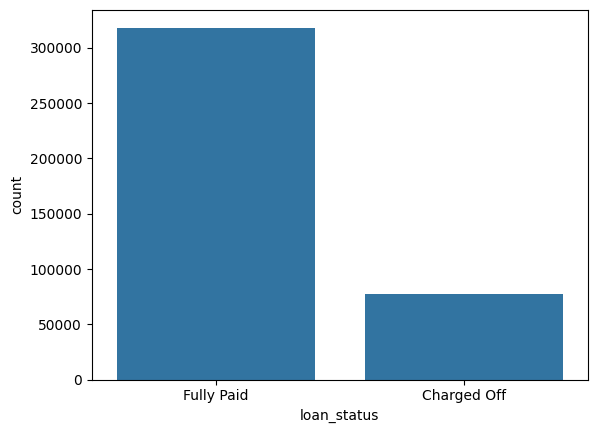

In [43]:
sns.countplot(x="loan_status",data=df)
plt.show()

In [44]:
df["loan_status"].value_counts()*100/len(df)

,count
loan_status,
Fully Paid,80.387092
Charged Off,19.612908


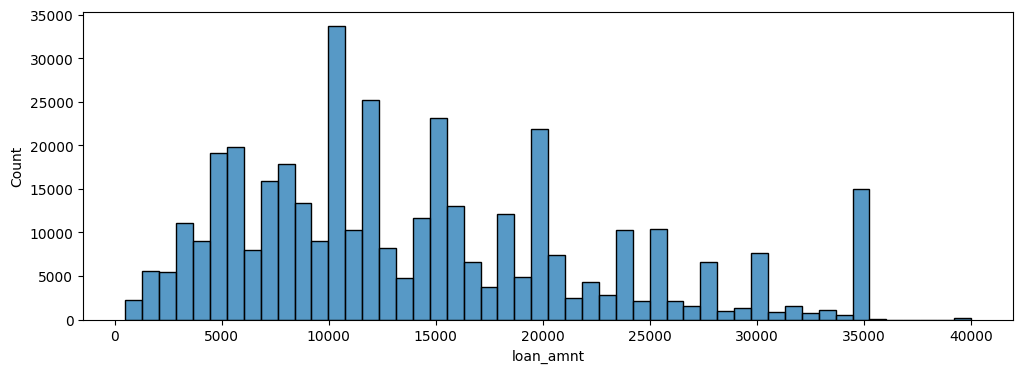

In [45]:
plt.figure(figsize=(12,4))
sns.histplot(df["loan_amnt"],bins=50)
plt.show()

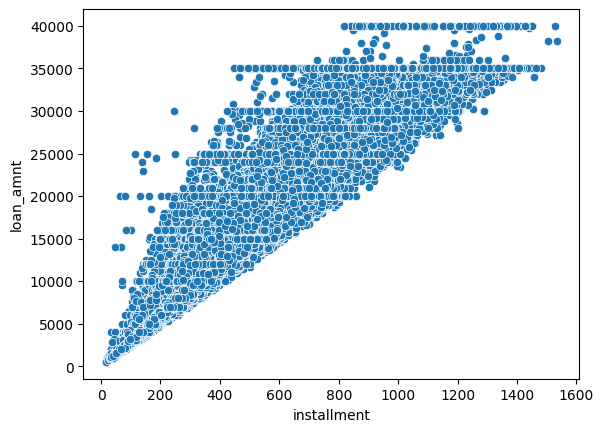

In [46]:
sns.scatterplot(x="installment",y="loan_amnt",data=df)
plt.show()

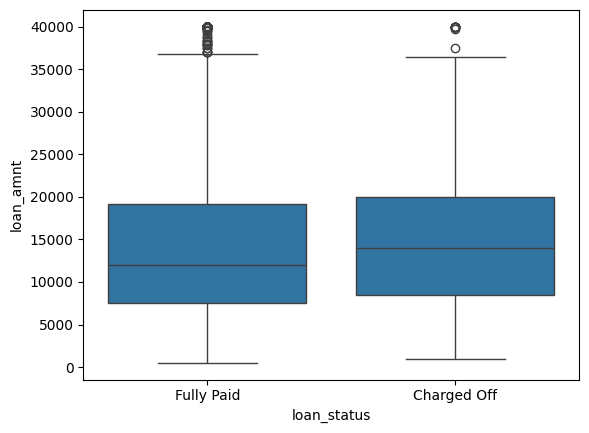

In [47]:
sns.boxplot(x="loan_status",y="loan_amnt",data=df)
plt.show()

In [48]:
df.groupby("loan_status")["loan_amnt"].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Charged Off,77673.0,15126.300967,8505.090557,1000.0,8525.0,14000.0,20000.0,40000.0
Fully Paid,318357.0,13866.878771,8302.319699,500.0,7500.0,12000.0,19225.0,40000.0


In [49]:
df["grade"].unique()

array(['B', 'A', 'C', 'E', 'D', 'F', 'G'], dtype=object)

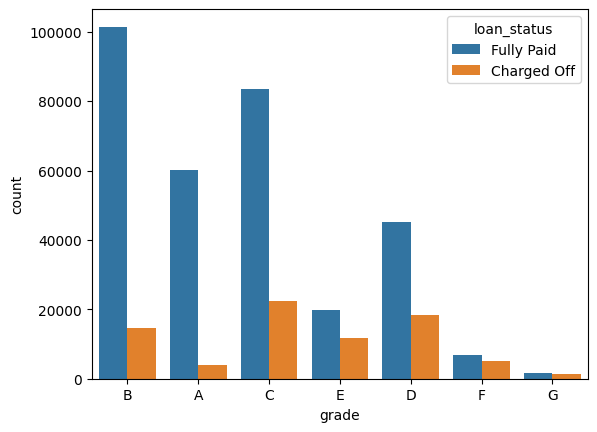

In [50]:
sns.countplot(x="grade",hue="loan_status",data=df)
plt.show()

In [51]:
df[df["grade"]=='A'].groupby("loan_status")["grade"].count()*100/len(df[df["grade"]=='A'])

,grade
loan_status,
Charged Off,6.287878
Fully Paid,93.712122


In [52]:
df[df["grade"]=='B'].groupby("loan_status")["grade"].count()*100/len(df[df["grade"]=='B'])

,grade
loan_status,
Charged Off,12.573049
Fully Paid,87.426951


In [53]:
df[df["grade"]=='G'].groupby("loan_status")["grade"].count()*100/len(df[df["grade"]=='G'])

,grade
loan_status,
Charged Off,47.8389
Fully Paid,52.1611


In [54]:
df["sub_grade"].unique()

array(['B4', 'B5', 'B3', 'A2', 'C5', 'C3', 'A1', 'B2', 'C1', 'A5', 'E4',
       'A4', 'A3', 'D1', 'C2', 'B1', 'D3', 'D5', 'D2', 'E1', 'E2', 'E5',
       'F4', 'E3', 'D4', 'G1', 'F5', 'G2', 'C4', 'F1', 'F3', 'G5', 'G4',
       'F2', 'G3'], dtype=object)

In [55]:
sub_order = sorted(df["sub_grade"].unique())

In [56]:
sub_order

['A1',
 'A2',
 'A3',
 'A4',
 'A5',
 'B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'E1',
 'E2',
 'E3',
 'E4',
 'E5',
 'F1',
 'F2',
 'F3',
 'F4',
 'F5',
 'G1',
 'G2',
 'G3',
 'G4',
 'G5']

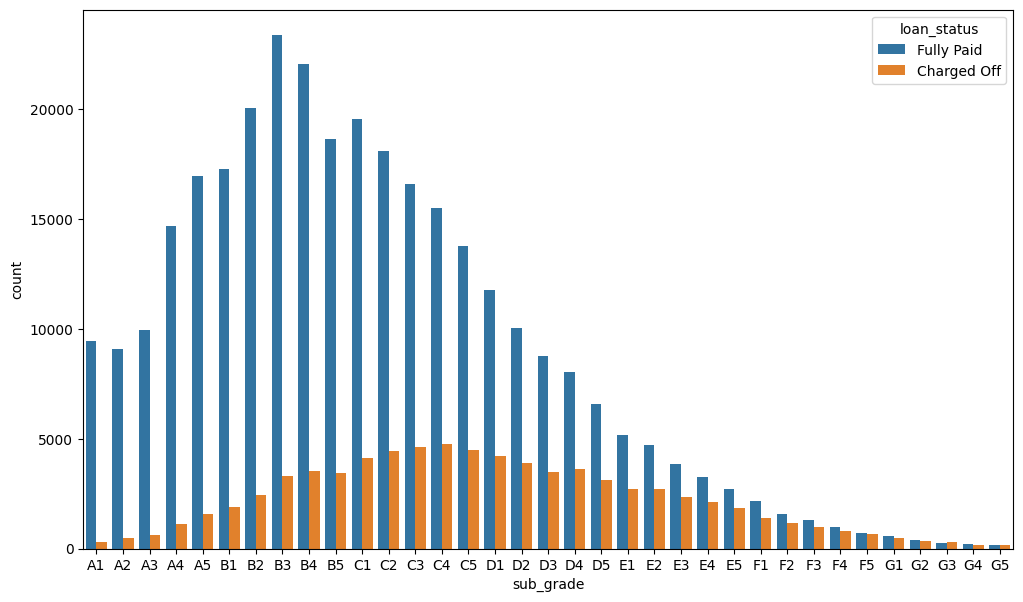

In [57]:
plt.figure(figsize=(12,7))
sns.countplot(x="sub_grade",hue="loan_status",order=sub_order,data=df)
plt.show()

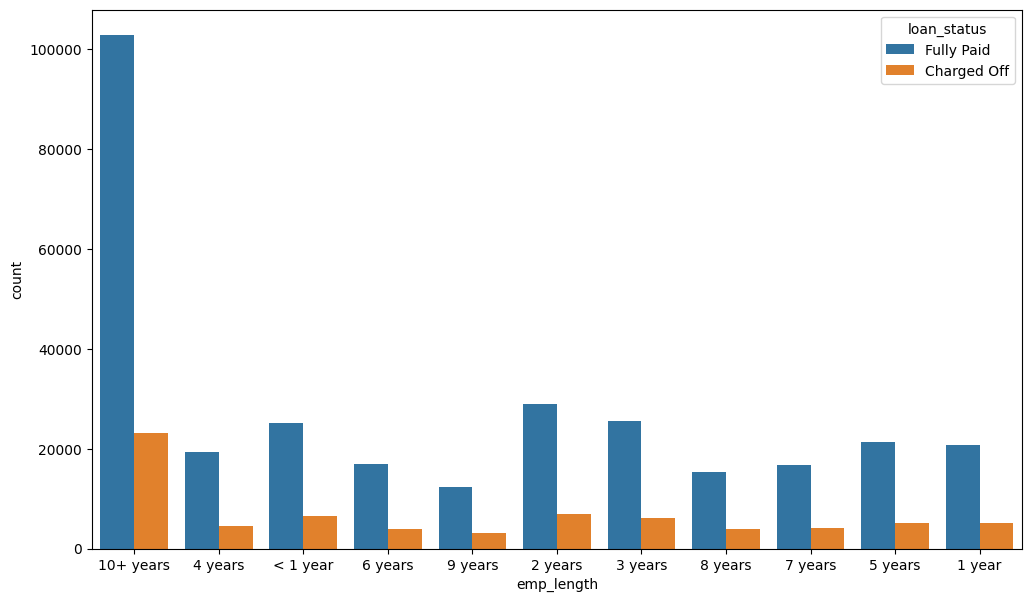

In [58]:
plt.figure(figsize=(12,7))
sns.countplot(x="emp_length",hue="loan_status",data=df)
plt.show()

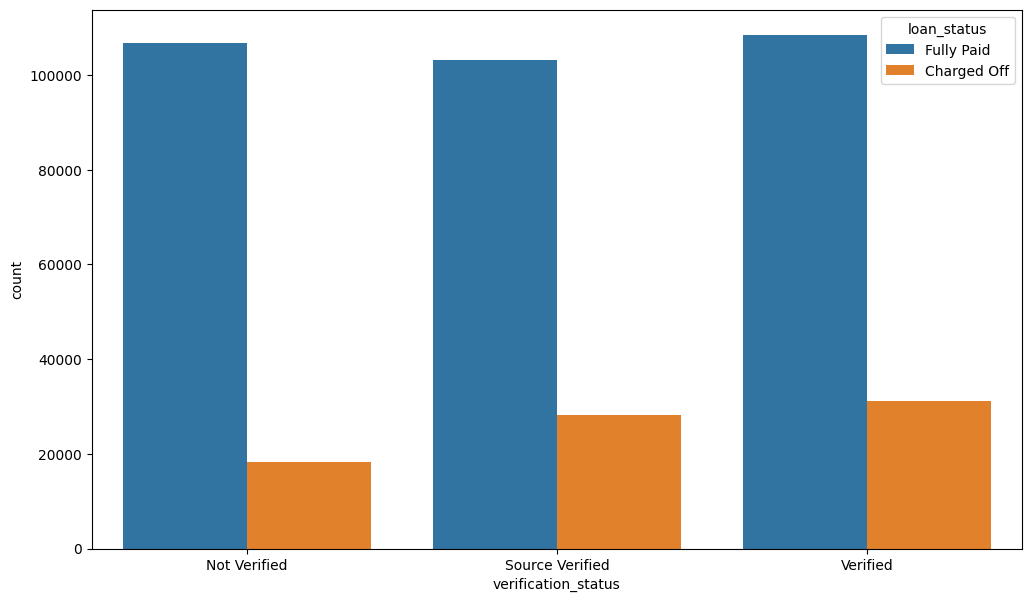

In [59]:
plt.figure(figsize=(12,7))
sns.countplot(x="verification_status",hue="loan_status",data=df)
plt.show()

In [60]:
df["loan_status"].apply(lambda x:1 if x=="Fully Paid" else 0)

,loan_status
0,1
1,1
2,1
3,1
4,0
...,...
396025,1
396026,1
396027,1
396028,1


In [61]:
print(df.shape)

(396030, 27)


In [62]:
# Display dataset information
df.info()

# Check loan status counts
print("\nLoan Status Distribution:")
print(df["loan_status"].value_counts(dropna=False))

# Display first five records
print("\nFirst five records:")
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396030 entries, 0 to 396029
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             396030 non-null  float64
 1   term                  396030 non-null  object 
 2   int_rate              396030 non-null  float64
 3   installment           396030 non-null  float64
 4   grade                 396030 non-null  object 
 5   sub_grade             396030 non-null  object 
 6   emp_title             373103 non-null  object 
 7   emp_length            377729 non-null  object 
 8   home_ownership        396030 non-null  object 
 9   annual_inc            396030 non-null  float64
 10  verification_status   396030 non-null  object 
 11  issue_d               396030 non-null  object 
 12  loan_status           396030 non-null  object 
 13  purpose               396030 non-null  object 
 14  title                 394274 non-null  object 
 15  

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\nGreggshire, VA 11650"


In [63]:

# Check the target variable
print(df["loan_status"].value_counts(dropna=False))

# Calculate percentages
print("\nPercentage distribution:")
print(df["loan_status"].value_counts(normalize=True) * 100)


loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64

Percentage distribution:
loan_status
Fully Paid     80.387092
Charged Off    19.612908
Name: proportion, dtype: float64


In [64]:
print("Dataset shape:", df.shape)
print("Unique loan statuses:", df["loan_status"].unique())
print("Missing target values:", df["loan_status"].isna().sum())

Dataset shape: (396030, 27)
Unique loan statuses: ['Fully Paid' 'Charged Off']
Missing target values: 0


In [65]:

# Convert issue_d into proper datetime format
issue_dates = pd.to_datetime(
    df["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

# Find minimum and maximum dates
print("Earliest loan issue date:", issue_dates.min())
print("Latest loan issue date:", issue_dates.max())

# Count invalid or missing dates
print("Missing/invalid issue dates:", issue_dates.isna().sum())

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())


Earliest loan issue date: 2007-06-01 00:00:00
Latest loan issue date: 2016-12-01 00:00:00
Missing/invalid issue dates: 0
Duplicate rows: 0


In [66]:

# Check the original date column
print("Column data type:")
print(df["issue_d"].dtype)

print("\nFirst 15 date values:")
print(df["issue_d"].head(15).to_list())

print("\nUnique date examples:")
print(df["issue_d"].dropna().unique()[:15])

print("\nMissing date values:")
print(df["issue_d"].isna().sum())


Column data type:
object

First 15 date values:
['Jan-2015', 'Jan-2015', 'Jan-2015', 'Nov-2014', 'Apr-2013', 'Sep-2015', 'Sep-2015', 'Sep-2012', 'Oct-2014', 'Apr-2012', 'Jun-2013', 'May-2014', 'Dec-2015', 'Apr-2015', 'Oct-2012']

Unique date examples:
['Jan-2015' 'Nov-2014' 'Apr-2013' 'Sep-2015' 'Sep-2012' 'Oct-2014'
 'Apr-2012' 'Jun-2013' 'May-2014' 'Dec-2015' 'Apr-2015' 'Oct-2012'
 'Jul-2014' 'Feb-2013' 'Oct-2015']

Missing date values:
0


In [67]:

# Convert issue_d into datetime format
df["issue_d"] = pd.to_datetime(
    df["issue_d"],
    format="%b-%y",
    errors="coerce"
)

# Check date range
print("Earliest loan issue date:", df["issue_d"].min())
print("Latest loan issue date:", df["issue_d"].max())

# Check missing dates
print("Missing dates:", df["issue_d"].isna().sum())

# Display first five dates
print("\nConverted dates:")
print(df["issue_d"].head())


Earliest loan issue date: NaT
Latest loan issue date: NaT
Missing dates: 396030

Converted dates:
0   NaT
1   NaT
2   NaT
3   NaT
4   NaT
Name: issue_d, dtype: datetime64[ns]


In [68]:

# Analyze loans issued in each year
print("Year-wise loan records:")

print(
    df["issue_d"]
    .dt.year
    .value_counts()
    .sort_index()
)

# Check the complete date range
print("\nDataset date range:")
print(df["issue_d"].min(), "to", df["issue_d"].max())

# Check target distribution
print("\nLoan status:")
print(df["loan_status"].value_counts())


Year-wise loan records:
Series([], Name: count, dtype: int64)

Dataset date range:
NaT to NaT

Loan status:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


In [69]:
df = pd.read_csv('/content/lending_club_loan_two.csv')

print("Dataset shape:", df.shape)

Dataset shape: (396030, 27)


In [70]:
print("Dataset shape:", df.shape)

print("\nLoan status counts:")
print(df["loan_status"].value_counts(dropna=False))

print("\nMissing target values:")
print(df["loan_status"].isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape: (396030, 27)

Loan status counts:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64

Missing target values:
0

Duplicate rows:
0


In [71]:
# Create a copy so the original dataset remains unchanged
df_ml = df.copy()

# Convert loan_status into numerical values
df_ml["loan_status"] = df_ml["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

# Check the result
print(df_ml["loan_status"].value_counts())

print("\nTarget data type:")
print(df_ml["loan_status"].dtype)

loan_status
0    318357
1     77673
Name: count, dtype: int64

Target data type:
int64


In [72]:
# Display all column names
print(df_ml.columns.tolist())

['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'address']


In [73]:
# Remove columns that we don't need initially
drop_columns = [
    "loan_status",
    "emp_title",
    "sub_grade",
    "title",
    "address"
]

# Create input features
X = df_ml.drop(columns=drop_columns)

# Create target variable
y = df_ml["loan_status"]

# Check the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display remaining columns
print("\nSelected features:")
print(X.columns.tolist())

Features shape: (396030, 22)
Target shape: (396030,)

Selected features:
['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'purpose', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies']


In [74]:
# Count missing values in each feature
missing_values = X.isnull().sum()

# Display only columns with missing values
print(missing_values[missing_values > 0].sort_values(ascending=False))

mort_acc                37795
emp_length              18301
pub_rec_bankruptcies      535
revol_util                276
dtype: int64


In [75]:
# Check data types of all selected features
print(X.dtypes)

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
purpose                  object
dti                     float64
earliest_cr_line         object
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object


In [76]:
# Inspect date columns
print("Issue date examples:")
print(X["issue_d"].head())

print("\nEarliest credit line examples:")
print(X["earliest_cr_line"].head())

Issue date examples:
0    Jan-2015
1    Jan-2015
2    Jan-2015
3    Nov-2014
4    Apr-2013
Name: issue_d, dtype: object

Earliest credit line examples:
0    Jun-1990
1    Jul-2004
2    Aug-2007
3    Sep-2006
4    Mar-1999
Name: earliest_cr_line, dtype: object


In [77]:
# Convert issue date into datetime
X["issue_d"] = pd.to_datetime(
    X["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

# Convert earliest credit line into datetime
X["earliest_cr_line"] = pd.to_datetime(
    X["earliest_cr_line"],
    format="%b-%Y",
    errors="coerce"
)

# Check the conversion
print(X[["issue_d", "earliest_cr_line"]].head())

print("\nMissing dates:")
print(X[["issue_d", "earliest_cr_line"]].isnull().sum())

     issue_d earliest_cr_line
0 2015-01-01       1990-06-01
1 2015-01-01       2004-07-01
2 2015-01-01       2007-08-01
3 2014-11-01       2006-09-01
4 2013-04-01       1999-03-01

Missing dates:
issue_d             0
earliest_cr_line    0
dtype: int64


In [78]:
# Extract issue year and month
X["issue_year"] = X["issue_d"].dt.year
X["issue_month"] = X["issue_d"].dt.month

# Calculate credit history length in years
X["credit_history_years"] = (
    (X["issue_d"] - X["earliest_cr_line"]).dt.days / 365.25
)

# Remove original date columns
X = X.drop(columns=["issue_d", "earliest_cr_line"])

# Display new features
print(X[["issue_year", "issue_month", "credit_history_years"]].head())

   issue_year  issue_month  credit_history_years
0        2015            1             24.585900
1        2015            1             10.502396
2        2015            1              7.419576
3        2014           11              8.167009
4        2013            4             14.086242


In [79]:
# Check the updated feature dataset
print("Updated feature shape:", X.shape)

# Count missing values
missing_values = X.isnull().sum()

print("\nMissing values:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

# Separate numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumber of numerical features:", len(numerical_features))
print("Numerical features:", numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:", categorical_features)

Updated feature shape: (396030, 23)

Missing values:
mort_acc                37795
emp_length              18301
pub_rec_bankruptcies      535
revol_util                276
dtype: int64

Number of numerical features: 13
Numerical features: ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'credit_history_years']

Number of categorical features: 8
Categorical features: ['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'initial_list_status', 'application_type']


In [80]:
# Identify all numerical columns, including int32
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nTotal selected features:",
      len(numerical_features) + len(categorical_features))

Numerical features: 15
['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'issue_year', 'issue_month', 'credit_history_years']

Categorical features: 8
['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'initial_list_status', 'application_type']

Total selected features: 23


In [81]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (316824, 23)
X_test: (79206, 23)
y_train: (316824,)
y_test: (79206,)


In [82]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Preprocessing pipeline for numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 2. Preprocessing pipeline for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 3. Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# 4. Fit on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# 5. Transform test data using the training-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# 6. Check the results
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nMissing values in processed training data:",
      __import__("numpy").isnan(X_train_processed.data if hasattr(X_train_processed, "data") and not isinstance(X_train_processed, __import__("numpy").ndarray) else X_train_processed).sum())

Training data shape: (316824, 63)
Testing data shape: (79206, 63)

Missing values in processed training data: 0


In [83]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [84]:
# Predict loan outcomes
y_pred = log_model.predict(X_test_processed)

# Predict probabilities
y_pred_proba = log_model.predict_proba(X_test_processed)[:, 1]

# Display first 10 predictions
print("Actual values:")
print(y_test.iloc[:10].values)

print("\nPredicted values:")
print(y_pred[:10])

print("\nDefault probabilities:")
print(y_pred_proba[:10])

Actual values:
[0 0 1 0 0 0 0 0 0 0]

Predicted values:
[0 0 0 0 0 0 0 0 0 0]

Default probabilities:
[0.10853494 0.21279833 0.31283872 0.08662478 0.26253676 0.20177027
 0.2850236  0.10459958 0.23126599 0.24590118]


In [85]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ROC-AUC score
print("\nROC-AUC:", roc_auc_score(y_test, y_pred_proba))

Accuracy: 0.8063783046738884

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.99      0.89     63671
           1       0.56      0.06      0.11     15535

    accuracy                           0.81     79206
   macro avg       0.68      0.52      0.50     79206
weighted avg       0.76      0.81      0.74     79206


Confusion Matrix:
[[62909   762]
 [14574   961]]

ROC-AUC: 0.70831866786312


In [86]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=100,
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [87]:
# Make predictions
dt_pred = dt_model.predict(X_test_processed)

# Calculate probabilities of default
dt_pred_proba = dt_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nROC-AUC:", roc_auc_score(y_test, dt_pred_proba))

Accuracy: 0.8066939373279802

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.98      0.89     63671
           1       0.55      0.08      0.14     15535

    accuracy                           0.81     79206
   macro avg       0.68      0.53      0.52     79206
weighted avg       0.76      0.81      0.74     79206


Confusion Matrix:
[[62621  1050]
 [14261  1274]]

ROC-AUC: 0.7130558073778416


In [88]:
from sklearn.ensemble import RandomForestClassifier

# Create a smaller Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=30,
    max_depth=8,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [89]:
# Make predictions
rf_pred = rf_model.predict(X_test_processed)

# Calculate default probabilities
rf_pred_proba = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nROC-AUC:", roc_auc_score(y_test, rf_pred_proba))# Make predictions
rf_pred = rf_model.predict(X_test_processed)

# Calculate default probabilities
rf_pred_proba = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nROC-AUC:", roc_auc_score(y_test, rf_pred_proba))

Accuracy: 0.6448375123096735

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.64      0.74     63671
           1       0.31      0.67      0.43     15535

    accuracy                           0.64     79206
   macro avg       0.60      0.66      0.58     79206
weighted avg       0.78      0.64      0.68     79206


Confusion Matrix:
[[40619 23052]
 [ 5079 10456]]

ROC-AUC: 0.7119798390095706
Accuracy: 0.6448375123096735

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.64      0.74     63671
           1       0.31      0.67      0.43     15535

    accuracy                           0.64     79206
   macro avg       0.60      0.66      0.58     79206
weighted avg       0.78      0.64      0.68     79206


Confusion Matrix:
[[40619 23052]
 [ 5079 10456]]

ROC-AUC: 0.7119798390095706


In [90]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
import numpy as np

# Split the training data into a smaller training set and validation set
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train Random Forest on the smaller training set
rf_tuning_model = RandomForestClassifier(
    n_estimators=30,
    max_depth=8,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

rf_tuning_model.fit(X_fit, y_fit)

# Get default probabilities on validation data
val_probabilities = rf_tuning_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, val_probabilities
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find the threshold with the highest F1-score
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Best Precision:", precision[best_index])
print("Best Recall:", recall[best_index])
print("Best F1-score:", f1_scores[best_index])

Best Threshold: 0.5334334305753722
Best Precision: 0.3352536620221508
Best Recall: 0.6040392661731574
Best F1-score: 0.4311889718093499


In [91]:
best_threshold = 0.5334334305753722

rf_pred_tuned = (
    rf_pred_proba >= best_threshold
).astype(int)

print("Tuned Threshold:", best_threshold)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred_tuned))

Tuned Threshold: 0.5334334305753722

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.72      0.79     63671
           1       0.34      0.58      0.43     15535

    accuracy                           0.69     79206
   macro avg       0.61      0.65      0.61     79206
weighted avg       0.77      0.69      0.72     79206


Confusion Matrix:
[[45877 17794]
 [ 6487  9048]]


In [92]:
from sklearn.metrics import precision_score, recall_score, f1_score

best_threshold = 0.5334334305753722

rf_pred_tuned = (rf_pred_proba >= best_threshold).astype(int)

print("Precision:", precision_score(y_test, rf_pred_tuned))
print("Recall:", recall_score(y_test, rf_pred_tuned))
print("F1-score:", f1_score(y_test, rf_pred_tuned))

Precision: 0.33708367483794055
Recall: 0.5824267782426779
F1-score: 0.4270240932581353


In [93]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest (Default Threshold)",
        "Random Forest (Tuned Threshold)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, rf_pred_tuned)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, rf_pred_tuned)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, rf_pred_tuned)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, rf_pred_tuned)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, log_model.predict_proba(X_test_processed)[:, 1]),
        roc_auc_score(y_test, dt_pred_proba),
        roc_auc_score(y_test, rf_pred_proba),
        roc_auc_score(y_test, rf_pred_proba)
    ]
})

print(results.round(4))

                               Model  Accuracy  Precision  Recall  F1 Score  \
0                Logistic Regression    0.8064     0.5577  0.0619    0.1114   
1                      Decision Tree    0.8067     0.5482  0.0820    0.1427   
2  Random Forest (Default Threshold)    0.6448     0.3120  0.6731    0.4264   
3    Random Forest (Tuned Threshold)    0.6934     0.3371  0.5824    0.4270   

   ROC-AUC  
0   0.7083  
1   0.7131  
2   0.7120  
3   0.7120  


                                  Feature  Importance
1                           num__int_rate    0.242118
17                           cat__grade_A    0.125459
16                   cat__term_ 60 months    0.090842
15                   cat__term_ 36 months    0.077389
18                           cat__grade_B    0.076525
4                                num__dti    0.061264
21                           cat__grade_E    0.045941
12                        num__issue_year    0.044466
3                         num__annual_inc    0.037060
20                           cat__grade_D    0.033688
8                         num__revol_util    0.021349
10                          num__mort_acc    0.021066
22                           cat__grade_F    0.017239
19                           cat__grade_C    0.014585
41  cat__verification_status_Not Verified    0.014334
36           cat__home_ownership_MORTGAGE    0.012252
2                        num__installment    0.010074
0                          n

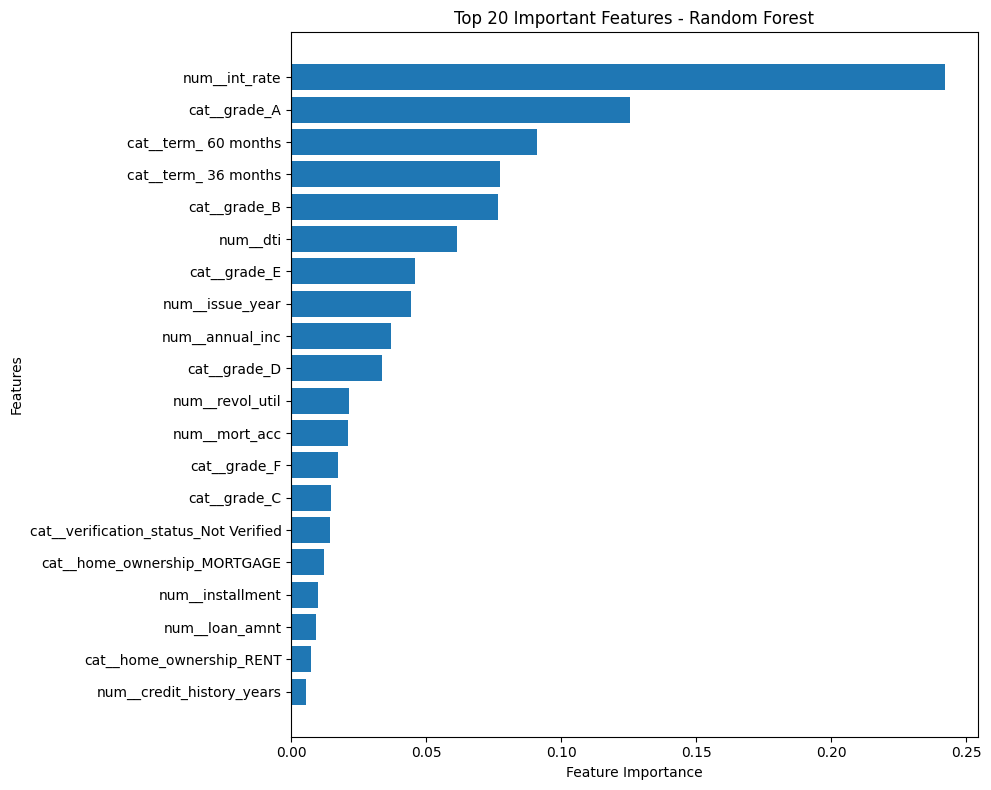

In [94]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importance = rf_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
print(feature_importance.head(20))

# Plot top 20 features
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance.head(20)["Feature"][::-1],
    feature_importance.head(20)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [95]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance
perm_result = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="f1",
    n_jobs=2
)

# Create importance DataFrame
perm_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_result.importances_mean
})

# Sort importance
perm_importance = perm_importance.sort_values(
    by="Importance",
    ascending=False
)

print(perm_importance.head(20))

                                  Feature  Importance
1                           num__int_rate    0.013722
12                        num__issue_year    0.008907
3                         num__annual_inc    0.005319
4                                num__dti    0.005155
15                   cat__term_ 36 months    0.002572
19                           cat__grade_C    0.002552
18                           cat__grade_B    0.002481
17                           cat__grade_A    0.001948
10                          num__mort_acc    0.001927
16                   cat__term_ 60 months    0.001823
21                           cat__grade_E    0.001771
41  cat__verification_status_Not Verified    0.001374
2                        num__installment    0.001137
36           cat__home_ownership_MORTGAGE    0.000947
14              num__credit_history_years    0.000930
8                         num__revol_util    0.000760
43      cat__verification_status_Verified    0.000655
45               cat__purpos

In [96]:
from sklearn.model_selection import train_test_split

# Split original training data into training and validation
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("New training shape:", X_train_new.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

New training shape: (253459, 23)
Validation shape: (63365, 23)
Test shape: (79206, 23)


In [97]:
# Fit preprocessing only on new training data
X_train_new_processed = preprocessor.fit_transform(X_train_new)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_new_processed = preprocessor.transform(X_test)

print("Training:", X_train_new_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_new_processed.shape)

Training: (253459, 63)
Validation: (63365, 63)
Test: (79206, 63)


In [98]:
from sklearn.ensemble import RandomForestClassifier

rf_final_candidate = RandomForestClassifier(
    n_estimators=30,
    max_depth=8,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

rf_final_candidate.fit(
    X_train_new_processed,
    y_train_new
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [99]:
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import numpy as np

# Get default probabilities for validation data
y_val_proba = rf_final_candidate.predict_proba(
    X_val_processed
)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

# Calculate F1 score
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find threshold with highest F1
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Validation Threshold:", best_threshold)
print("Validation Precision:", precision[best_index])
print("Validation Recall:", recall[best_index])
print("Validation F1-score:", f1_scores[best_index])

Best Validation Threshold: 0.5334334305753722
Validation Precision: 0.3352536620221508
Validation Recall: 0.6040392661731574
Validation F1-score: 0.4311889718093499


In [100]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict probabilities on untouched test data
y_test_proba = rf_final_candidate.predict_proba(
    X_test_new_processed
)[:, 1]

# Apply the validation-selected threshold
y_test_pred_final = (
    y_test_proba >= best_threshold
).astype(int)

# Evaluate final model
print("Final Test Accuracy:",
      accuracy_score(y_test, y_test_pred_final))

print("\nFinal Classification Report:")
print(classification_report(y_test, y_test_pred_final))

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

print("\nFinal ROC-AUC:",
      roc_auc_score(y_test, y_test_proba))

Final Test Accuracy: 0.6856551271368331

Final Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.71      0.78     63671
           1       0.33      0.60      0.43     15535

    accuracy                           0.69     79206
   macro avg       0.61      0.65      0.61     79206
weighted avg       0.77      0.69      0.71     79206


Final Confusion Matrix:
[[44966 18705]
 [ 6193  9342]]

Final ROC-AUC: 0.7122395447748404


In [101]:
# Count loans by issue year
year_counts = X["issue_year"].value_counts().sort_index()

print("Loan records by year:")
print(year_counts)

Loan records by year:
issue_year
2007       195
2008      1240
2009      3826
2010      9258
2011     17435
2012     41202
2013     97662
2014    102860
2015     94264
2016     28088
Name: count, dtype: int64


In [102]:
# Create chronological data masks
train_mask = X["issue_year"] <= 2014
val_mask = X["issue_year"] == 2015
test_mask = X["issue_year"] == 2016

# Split features
X_time_train = X.loc[train_mask].copy()
X_time_val = X.loc[val_mask].copy()
X_time_test = X.loc[test_mask].copy()

# Split target
y_time_train = y.loc[train_mask].copy()
y_time_val = y.loc[val_mask].copy()
y_time_test = y.loc[test_mask].copy()

# Display dataset shapes
print("Training shape:", X_time_train.shape)
print("Validation shape:", X_time_val.shape)
print("Test shape:", X_time_test.shape)

Training shape: (273678, 23)
Validation shape: (94264, 23)
Test shape: (28088, 23)


In [103]:
print("Training target distribution:")
print(y_time_train.value_counts(normalize=True).sort_index())

print("\nValidation target distribution:")
print(y_time_val.value_counts(normalize=True).sort_index())

print("\nTest target distribution:")
print(y_time_test.value_counts(normalize=True).sort_index())

Training target distribution:
loan_status
0    0.815433
1    0.184567
Name: proportion, dtype: float64

Validation target distribution:
loan_status
0    0.750987
1    0.249013
Name: proportion, dtype: float64

Test target distribution:
loan_status
0    0.868698
1    0.131302
Name: proportion, dtype: float64


In [104]:
# Fit on training data
X_time_train_processed = preprocessor.fit_transform(
    X_time_train
)

# Transform validation and test data
X_time_val_processed = preprocessor.transform(
    X_time_val
)

X_time_test_processed = preprocessor.transform(
    X_time_test
)

print("Processed training:", X_time_train_processed.shape)
print("Processed validation:", X_time_val_processed.shape)
print("Processed test:", X_time_test_processed.shape)

Processed training: (273678, 60)
Processed validation: (94264, 60)
Processed test: (28088, 60)


In [105]:
rf_time = RandomForestClassifier(
    n_estimators=30,
    max_depth=8,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

rf_time.fit(X_time_train_processed, y_time_train)

print("Time-based Random Forest training completed!")

Time-based Random Forest training completed!


In [106]:
y_time_val_proba = rf_time.predict_proba(
    X_time_val_processed
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_time_val, y_time_val_proba
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)
best_time_threshold = thresholds[best_idx]

print("Best validation threshold:", best_time_threshold)
print("Validation precision:", precision[best_idx])
print("Validation recall:", recall[best_idx])
print("Validation F1-score:", f1_scores[best_idx])

Best validation threshold: 0.5571313460543591
Validation precision: 0.3848531296328869
Validation recall: 0.6524943552166319
Validation F1-score: 0.48414730515326515


In [107]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Predict default probabilities for 2016
y_time_test_proba = rf_time.predict_proba(
    X_time_test_processed
)[:, 1]

# Apply the fixed threshold selected using 2015
y_time_test_pred = (
    y_time_test_proba >= best_time_threshold
).astype(int)

print("Classification Report:")
print(classification_report(
    y_time_test,
    y_time_test_pred,
    target_names=["Fully Paid", "Charged Off"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_time_test, y_time_test_pred))

print("Accuracy:", accuracy_score(
    y_time_test, y_time_test_pred
))

print("ROC-AUC:", roc_auc_score(
    y_time_test, y_time_test_proba
))

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.92      0.64      0.75     24400
 Charged Off       0.21      0.64      0.32      3688

    accuracy                           0.64     28088
   macro avg       0.57      0.64      0.54     28088
weighted avg       0.83      0.64      0.70     28088

Confusion Matrix:
[[15540  8860]
 [ 1313  2375]]
Accuracy: 0.6378168612930789
ROC-AUC: 0.6900976527772839


In [108]:
# Check actual and predicted class distributions
print("Actual 2016 outcomes:")
print(y_time_test.value_counts(normalize=True).sort_index())

print("\nPredicted 2016 outcomes:")
print(pd.Series(y_time_test_pred).value_counts(normalize=True).sort_index())

Actual 2016 outcomes:
loan_status
0    0.868698
1    0.131302
Name: proportion, dtype: float64

Predicted 2016 outcomes:
0    0.600007
1    0.399993
Name: proportion, dtype: float64


In [109]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_time.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                 Feature  Importance
1          num__int_rate    0.260167
16  cat__term_ 60 months    0.160263
17          cat__grade_A    0.110400
15  cat__term_ 36 months    0.079153
18          cat__grade_B    0.062579
12       num__issue_year    0.048271
3        num__annual_inc    0.046031
4               num__dti    0.035873
20          cat__grade_D    0.031270
21          cat__grade_E    0.025124
10         num__mort_acc    0.018554
19          cat__grade_C    0.015535
22          cat__grade_F    0.014835
2       num__installment    0.013238
8        num__revol_util    0.011709


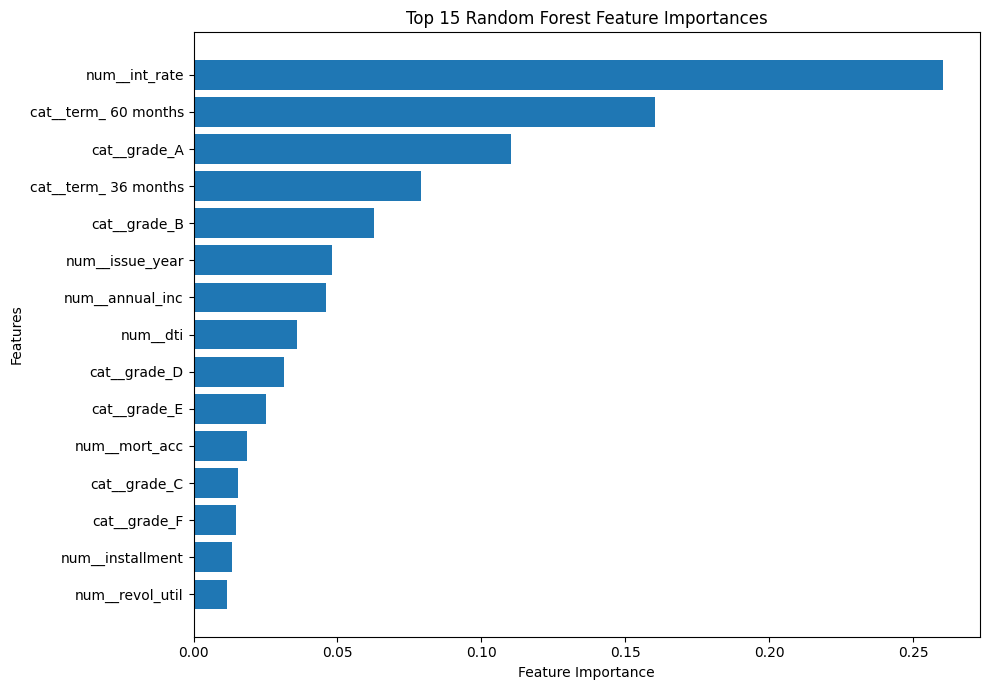

In [110]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

In [111]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_time,
    X_time_val_processed,
    y_time_val,
    n_repeats=3,
    random_state=42,
    scoring="f1",
    n_jobs=2
)

perm_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_result.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

print(perm_importance_df.head(15))

                         Feature  Importance
1                  num__int_rate    0.022828
4                       num__dti    0.004352
3                num__annual_inc    0.003889
18                  cat__grade_B    0.002782
17                  cat__grade_A    0.002655
10                 num__mort_acc    0.002216
16          cat__term_ 60 months    0.001786
19                  cat__grade_C    0.001198
35  cat__home_ownership_MORTGAGE    0.000938
8                num__revol_util    0.000888
21                  cat__grade_E    0.000848
2               num__installment    0.000751
20                  cat__grade_D    0.000742
39      cat__home_ownership_RENT    0.000651
15          cat__term_ 36 months    0.000634


In [112]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_test = [
    0.5571,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80
]

results = []

for threshold in thresholds_to_test:

    val_pred = (
        y_time_val_proba >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_time_val, val_pred),
        "Recall": recall_score(y_time_val, val_pred),
        "F1 Score": f1_score(y_time_val, val_pred)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4))

   Threshold  Precision  Recall  F1 Score
0     0.5571     0.3847  0.6525    0.4841
1     0.6000     0.4144  0.5285    0.4645
2     0.6500     0.4521  0.3877    0.4174
3     0.7000     0.4883  0.2517    0.3322
4     0.7500     0.5379  0.1232    0.2004
5     0.8000     0.6334  0.0236    0.0454


In [113]:
valid_results = threshold_results[
    threshold_results["Precision"] >= 0.45
]

print(valid_results.sort_values(
    by="Recall",
    ascending=False
))

   Threshold  Precision    Recall  F1 Score
2       0.65   0.452111  0.387722  0.417448
3       0.70   0.488345  0.251693  0.332181
4       0.75   0.537860  0.123163  0.200430
5       0.80   0.633448  0.023559  0.045428


In [114]:
# Alternative threshold selected using 2015 validation
alternative_threshold = 0.65

y_test_pred_065 = (
    y_time_test_proba >= alternative_threshold
).astype(int)

print("Classification Report at threshold 0.65:")
print(classification_report(
    y_time_test,
    y_test_pred_065,
    target_names=["Fully Paid", "Charged Off"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_time_test, y_test_pred_065))

print("Accuracy:",
      accuracy_score(y_time_test, y_test_pred_065))

Classification Report at threshold 0.65:
              precision    recall  f1-score   support

  Fully Paid       0.90      0.84      0.87     24400
 Charged Off       0.26      0.38      0.31      3688

    accuracy                           0.78     28088
   macro avg       0.58      0.61      0.59     28088
weighted avg       0.82      0.78      0.79     28088

Confusion Matrix:
[[20446  3954]
 [ 2293  1395]]
Accuracy: 0.7775918541726003


In [115]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

configs = [
    {"n_estimators": 30, "max_depth": 6, "min_samples_leaf": 100},
    {"n_estimators": 30, "max_depth": 10, "min_samples_leaf": 100},
    {"n_estimators": 30, "max_depth": 8, "min_samples_leaf": 200}
]

tuning_results = []

for i, config in enumerate(configs):

    model = RandomForestClassifier(
        **config,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    )

    model.fit(X_time_train_processed, y_time_train)

    val_proba = model.predict_proba(
        X_time_val_processed
    )[:, 1]

    val_pred = (val_proba >= best_time_threshold).astype(int)

    tuning_results.append({
        "Configuration": i + 1,
        "Max Depth": config["max_depth"],
        "Min Samples Leaf": config["min_samples_leaf"],
        "Precision": precision_score(y_time_val, val_pred),
        "Recall": recall_score(y_time_val, val_pred),
        "F1 Score": f1_score(y_time_val, val_pred),
        "ROC-AUC": roc_auc_score(y_time_val, val_proba)
    })

tuning_df = pd.DataFrame(tuning_results)

print(tuning_df.round(4))

   Configuration  Max Depth  Min Samples Leaf  Precision  Recall  F1 Score  \
0              1          6               100     0.3888  0.5956    0.4705   
1              2         10               100     0.3877  0.6481    0.4852   
2              3          8               200     0.3830  0.6519    0.4825   

   ROC-AUC  
0   0.7017  
1   0.7118  
2   0.7063  


In [116]:
best_rf_time = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

best_rf_time.fit(
    X_time_train_processed,
    y_time_train
)

print("Best Random Forest model trained successfully!")

Best Random Forest model trained successfully!


In [117]:
import joblib
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_rf_time)
])

print("Complete pipeline created successfully!")

Complete pipeline created successfully!


In [118]:
joblib.dump(
    final_pipeline,
    "loan_default_rf_pipeline.joblib"
)

print("Model pipeline saved successfully!")

Model pipeline saved successfully!


In [119]:
from google.colab import files

files.download("loan_default_rf_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [120]:
import joblib

loaded_pipeline = joblib.load("loan_default_rf_pipeline.joblib")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [121]:
# Select 5 sample records
sample_loans = X_time_val.head(5)

# Predict default probabilities
default_probabilities = loaded_pipeline.predict_proba(sample_loans)[:, 1]

# Apply the validation-selected threshold
predictions = (default_probabilities >= best_time_threshold).astype(int)

# Display results
results = pd.DataFrame({
    "Default Probability": default_probabilities,
    "Predicted Status": [
        "Charged Off" if p == 1 else "Fully Paid"
        for p in predictions
    ]
})

print(results)

   Default Probability Predicted Status
0             0.437358       Fully Paid
1             0.377547       Fully Paid
2             0.403961       Fully Paid
3             0.479697       Fully Paid
4             0.151146       Fully Paid


In [122]:
import os

print(os.listdir("/content"))

['.config', 'loan_default_rf_pipeline.joblib', 'lending_club_loan_two.csv', 'sample_data']


In [123]:
from google.colab import files
uploaded = files.upload()

Saving lending_club_loan_two.csv to lending_club_loan_two (1).csv


In [124]:
import pandas as pd

df = pd.read_csv("lending_club_loan_two.csv")

print(df.shape)

(396030, 27)


In [125]:
import pandas as pd

df = pd.read_csv('/content/lending_club_loan_two.csv')

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (396030, 27)

First 5 rows:
   loan_amnt        term  int_rate  installment grade sub_grade  \
0    10000.0   36 months     11.44       329.48     B        B4   
1     8000.0   36 months     11.99       265.68     B        B5   
2    15600.0   36 months     10.49       506.97     B        B3   
3     7200.0   36 months      6.49       220.65     A        A2   
4    24375.0   60 months     17.27       609.33     C        C5   

                 emp_title emp_length home_ownership  annual_inc  ...  \
0                Marketing  10+ years           RENT    117000.0  ...   
1          Credit analyst     4 years       MORTGAGE     65000.0  ...   
2             Statistician   < 1 year           RENT     43057.0  ...   
3          Client Advocate    6 years           RENT     54000.0  ...   
4  Destiny Management Inc.    9 years       MORTGAGE     55000.0  ...   

  open_acc pub_rec revol_bal revol_util total_acc  initial_list_status  \
0     16.0     0.0   36369.0       41.8  

In [126]:
# Create a copy of the dataset
df_ml = df.copy()

# Convert target variable into numerical values
df_ml["loan_status"] = df_ml["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

# Remove unnecessary columns
drop_columns = [
    "loan_status",
    "emp_title",
    "sub_grade",
    "title",
    "address"
]

# Separate features and target
X = df_ml.drop(columns=drop_columns)
y = df_ml["loan_status"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (396030, 22)
Target shape: (396030,)

Target distribution:
loan_status
0    318357
1     77673
Name: count, dtype: int64


In [127]:
# Convert date columns
X["issue_d"] = pd.to_datetime(
    X["issue_d"], format="%b-%Y", errors="coerce"
)

X["earliest_cr_line"] = pd.to_datetime(
    X["earliest_cr_line"], format="%b-%Y", errors="coerce"
)

# Extract year and month
X["issue_year"] = X["issue_d"].dt.year
X["issue_month"] = X["issue_d"].dt.month

# Calculate credit history length
X["credit_history_years"] = (
    (X["issue_d"] - X["earliest_cr_line"]).dt.days / 365.25
)

# Remove original date columns
X = X.drop(columns=["issue_d", "earliest_cr_line"])

print("Final feature shape:", X.shape)

Final feature shape: (396030, 23)


In [128]:
# Create time-based masks
train_mask = X["issue_year"] <= 2014
val_mask = X["issue_year"] == 2015
test_mask = X["issue_year"] == 2016

# Split features
X_time_train = X.loc[train_mask].copy()
X_time_val = X.loc[val_mask].copy()
X_time_test = X.loc[test_mask].copy()

# Split target
y_time_train = y.loc[train_mask].copy()
y_time_val = y.loc[val_mask].copy()
y_time_test = y.loc[test_mask].copy()

# Display shapes
print("Training:", X_time_train.shape)
print("Validation:", X_time_val.shape)
print("Testing:", X_time_test.shape)

Training: (273678, 23)
Validation: (94264, 23)
Testing: (28088, 23)


In [129]:
print("Training years:",
      sorted(X_time_train["issue_year"].unique()))

print("Validation years:",
      sorted(X_time_val["issue_year"].unique()))

print("Testing years:",
      sorted(X_time_test["issue_year"].unique()))

Training years: [np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]
Validation years: [np.int32(2015)]
Testing years: [np.int32(2016)]


In [130]:
numerical_features = X_time_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_time_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 15
Categorical features: 8

Numerical columns:
['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'issue_year', 'issue_month', 'credit_history_years']

Categorical columns:
['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'initial_list_status', 'application_type']


In [131]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformers
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [132]:
X_time_train_processed = preprocessor.fit_transform(X_time_train)

X_time_val_processed = preprocessor.transform(X_time_val)

X_time_test_processed = preprocessor.transform(X_time_test)

print("Training:", X_time_train_processed.shape)
print("Validation:", X_time_val_processed.shape)
print("Testing:", X_time_test_processed.shape)

Training: (273678, 60)
Validation: (94264, 60)
Testing: (28088, 60)


In [133]:
from sklearn.ensemble import RandomForestClassifier

best_rf_time = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

best_rf_time.fit(
    X_time_train_processed,
    y_time_train
)

print("Best Random Forest model trained successfully!")

Best Random Forest model trained successfully!


In [134]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_rf_time)
])

print("Final pipeline created successfully!")

Final pipeline created successfully!


In [135]:
import joblib

joblib.dump(
    final_pipeline,
    "loan_default_rf_pipeline.joblib"
)

print("Model pipeline saved successfully!")

Model pipeline saved successfully!


In [136]:
from google.colab import files

files.download("loan_default_rf_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [137]:
print("Model available:", "best_rf_time" in globals())
print("Preprocessor available:", "preprocessor" in globals())
print("Pipeline available:", "final_pipeline" in globals())

Model available: True
Preprocessor available: True
Pipeline available: True


In [138]:
import pandas as pd

def predict_new_loan():

    print("===== LOAN DEFAULT PREDICTION SYSTEM =====")
    print("\nEnter the borrower's loan details:\n")

    # Numerical inputs
    loan_amnt = float(input("Loan Amount: "))
    int_rate = float(input("Interest Rate (%): "))
    installment = float(input("Monthly Installment: "))
    annual_inc = float(input("Annual Income: "))
    dti = float(input("Debt-to-Income Ratio: "))
    open_acc = float(input("Open Accounts: "))
    pub_rec = float(input("Public Records: "))
    revol_bal = float(input("Revolving Balance: "))
    revol_util = float(input("Revolving Utilization (%): "))
    total_acc = float(input("Total Accounts: "))
    mort_acc = float(input("Mortgage Accounts: "))
    pub_rec_bankruptcies = float(input("Public Record Bankruptcies: "))

    issue_year = int(input("Loan Issue Year (e.g. 2016): "))
    issue_month = int(input("Loan Issue Month (1-12): "))
    credit_history_years = float(input("Credit History (years): "))

    # Categorical inputs
    term = input("Loan Term (36 months / 60 months): ")
    grade = input("Loan Grade (A/B/C/D/E/F/G): ")
    emp_length = input("Employment Length (e.g. 10+ years): ")
    home_ownership = input("Home Ownership (RENT/MORTGAGE/OWN/OTHER): ")
    verification_status = input("Verification Status: ")
    purpose = input("Loan Purpose: ")
    initial_list_status = input("Initial List Status (w/f): ")
    application_type = input("Application Type (INDIVIDUAL/JOINT): ")

    # Create input DataFrame
    input_data = pd.DataFrame([{
        "loan_amnt": loan_amnt,
        "term": term,
        "int_rate": int_rate,
        "installment": installment,
        "grade": grade,
        "emp_length": emp_length,
        "home_ownership": home_ownership,
        "annual_inc": annual_inc,
        "verification_status": verification_status,
        "purpose": purpose,
        "dti": dti,
        "open_acc": open_acc,
        "pub_rec": pub_rec,
        "revol_bal": revol_bal,
        "revol_util": revol_util,
        "total_acc": total_acc,
        "initial_list_status": initial_list_status,
        "application_type": application_type,
        "mort_acc": mort_acc,
        "pub_rec_bankruptcies": pub_rec_bankruptcies,
        "issue_year": issue_year,
        "issue_month": issue_month,
        "credit_history_years": credit_history_years
    }])

    # Predict default probability
    probability = final_pipeline.predict_proba(input_data)[0][1]

    # Apply selected threshold
    threshold = 0.5571313460543591

    if probability >= threshold:
        prediction = "Charged Off"
    else:
        prediction = "Fully Paid"

    # Display results
    print("\n===== PREDICTION RESULTS =====")
    print(f"Default Probability: {probability * 100:.2f}%")
    print(f"Predicted Loan Status: {prediction}")

    if probability < 0.20:
        risk = "Low Risk"
    elif probability < threshold:
        risk = "Medium Risk"
    else:
        risk = "High Risk"

    print(f"Risk Category: {risk}")

    print("\n================================")

In [141]:
predict_new_loan()

===== LOAN DEFAULT PREDICTION SYSTEM =====

Enter the borrower's loan details:

Loan Amount: 10000
Interest Rate (%): 11.444
Monthly Installment: 329.18
Annual Income: 117000
Debt-to-Income Ratio: 15
Open Accounts: 16
Public Records: 0
Revolving Balance: 36369
Revolving Utilization (%): 41.8
Total Accounts: 25
Mortgage Accounts: 0
Public Record Bankruptcies: 0
Loan Issue Year (e.g. 2016): 2016
Loan Issue Month (1-12): 1
Credit History (years): 15
Loan Term (36 months / 60 months): 36months
Loan Grade (A/B/C/D/E/F/G): B
Employment Length (e.g. 10+ years): 10+years
Home Ownership (RENT/MORTGAGE/OWN/OTHER): RENT
Verification Status: Not Verified
Loan Purpose: debt_consolidation
Initial List Status (w/f): w
Application Type (INDIVIDUAL/JOINT): INDIVIDUAL

===== PREDICTION RESULTS =====
Default Probability: 38.22%
Predicted Loan Status: Fully Paid
Risk Category: Medium Risk

